# Table of Contents
- 1. Standardization vs Min-Max Scaling
- 2. Robust Scaler for Outlier-Heavy Data
- 3. Log, Box-Cox, and Yeo-Johnson Transformations
- 4. Quantile Uniform and Normal Transforms

In [ ]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, PowerTransformer, QuantileTransformer

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for numerical scaling and power transforms loaded successfully.")

---
## 1. Standardization vs Min-Max Scaling

### 1. Definition
Standardization centers data to zero mean and unit variance, whereas Min-Max scaling bounds features strictly within a specified range (typically $[0, 1]$).

### 2. Math Formula
For feature vector $x$, standardization and min-max scaling are defined as:
$$x_{std} = \frac{x - \mu}{\sigma}, \quad x_{minmax} = \frac{x - x_{min}}{x_{max} - x_{min}}$$

### 3. Notation Pronunciation
- $\mu$ and $\sigma$: "Mean and standard deviation"
- $x_{std}$: "Z-score standardized feature value"
- $x_{minmax}$: "Min-Max normalized feature value bounded in $[0, 1]$"

### 4. Naive Example
Scaling an apartment square footage feature (ranging from 500 to 5,000 sq ft) to a $[0,1]$ range so it matches a binary feature scale during gradient descent optimization.

### 5. Uses
- Preparing feature matrices for gradient-based models (Neural Networks, Logistic Regression).
- Ensuring distance-based algorithms (KNN, SVM) treat all features with equal weighting.
- Standardizing input distributions.

In [ ]:
np.random.seed(42)
x_data = np.random.normal(50, 10, 100).reshape(-1, 1)

scaler_std = StandardScaler() # mean = 0 and std = 1 : scales standard normal distribution
scaler_mm = MinMaxScaler() # min =0 and max =1 : scales fixed and bound range

print("_" * 60)

df_scaled = pd.DataFrame({
    'Standardized': scaler_std.fit_transform(x_data).flatten(),
    'MinMax': scaler_mm.fit_transform(x_data).flatten()
})
print(
    "Scaled Data Summary Statistics:\n",
    df_scaled.describe().round(2),
)


---
## 2. Robust Scaler for Outlier-Heavy Data

### 1. Definition
Robust Scaler scales features using statistics that are robust to outliers, specifically subtracting the median and dividing by the Interquartile Range (IQR).

### 2. Math Formula
For feature vector $x$ with median $Q_2(x)$, first quartile $Q_1(x)$, and third quartile $Q_3(x)$:
$$x_{robust} = \frac{x - Q_2(x)}{Q_3(x) - Q_1(x)}$$

### 3. Notation Pronunciation
- $Q_2$: "Median 50th percentile"
- $IQR$: "Interquartile range ($Q_3 - Q_1$)"
- `RobustScaler`: "Median and IQR-based feature scaling"

### 4. Naive Example
Scaling a customer income feature that contains extreme billionaire outliers without letting those outliers skew the scaling parameters.

### 5. Uses
- Preprocessing datasets with severe outliers where standardization would compress normal data into a narrow band.
- Robust feature engineering for linear models and anomaly detection.
- Preserving outlier separation while centering central tendencies.

In [ ]:
x_outliers = np.concatenate([np.random.normal(0, 1, 90), [20, 25, -22]]) # Contains outliers
scaler_rob = RobustScaler()
x_rob = scaler_rob.fit_transform(x_outliers.reshape(-1, 1)).flatten()

print("Robust Scaler Output Summary (Min/Max):", round(x_rob.min(), 2), round(x_rob.max(), 2))


### 1. Definition
Power transformations stabilize variance and make skewed data distributions more Gaussian (normal)

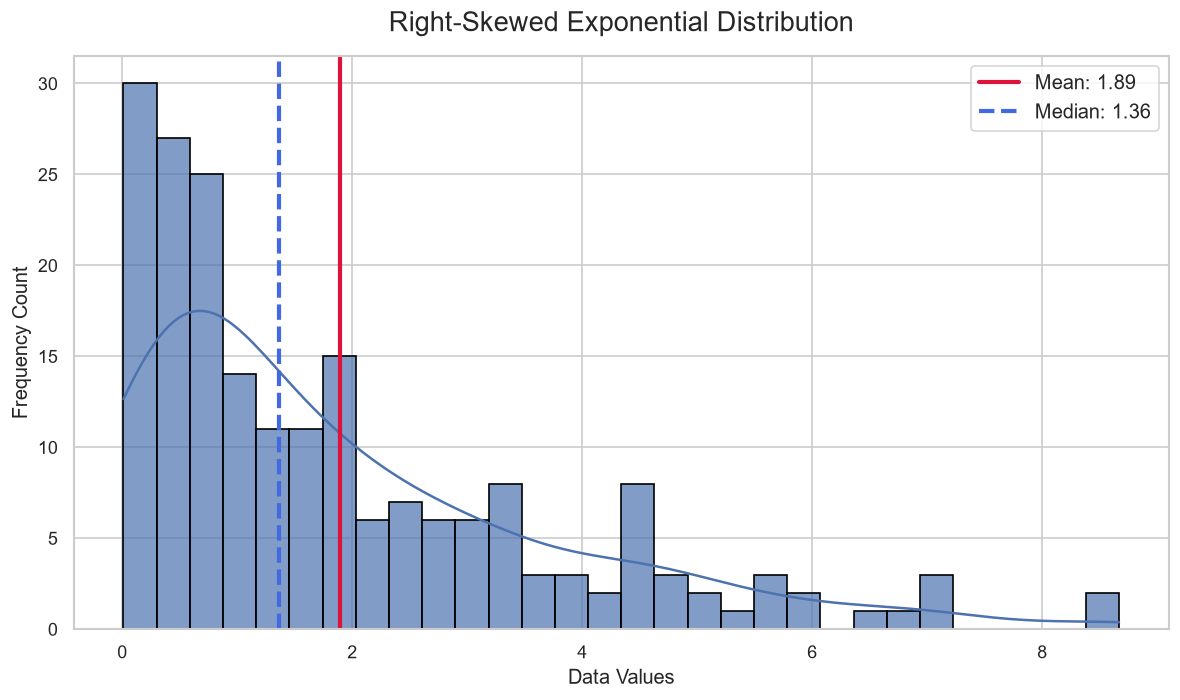

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate the right-skewed exponential data
skewed_data = np.random.exponential(scale=2, size=200).reshape(-1, 1)

# Calculate central tendencies to show the skew
data_mean = np.mean(skewed_data)
data_median = np.median(skewed_data)

# 2. Plotting the distribution
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Create the histogram with a Kernel Density Estimate (KDE) line
sns.histplot(
    skewed_data, kde=True, color="teal", bins=30, edgecolor="black", alpha=0.7
)

# Add vertical lines for mean and median to visualize the skew
plt.axvline(
    data_mean,
    color="crimson",
    linestyle="solid",
    linewidth=2.5,
    label=f"Mean: {data_mean:.2f}",
)
plt.axvline(
    data_median,
    color="royalblue",
    linestyle="dashed",
    linewidth=2.5,
    label=f"Median: {data_median:.2f}",
)

# Decorate the plot
plt.title("Right-Skewed Exponential Distribution", fontsize=16, pad=15)
plt.xlabel("Data Values", fontsize=12)
plt.ylabel("Frequency Count", fontsize=12)
plt.legend(fontsize=12, loc="upper right")

# Show the plot
plt.tight_layout()
plt.show()

Original Skew vs Transformed Skew: 1.38 -> 0.08


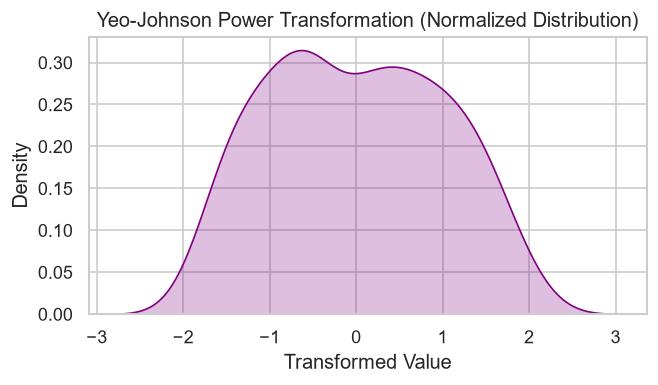

In [17]:
np.random.seed(42)
skewed_data = np.random.exponential(scale=2, size=200).reshape(-1, 1)
pt = PowerTransformer(method='yeo-johnson')
transformed_data = pt.fit_transform(skewed_data)

print(
    "Original Skew vs Transformed Skew:",
    round(pd.Series(skewed_data.flatten()).skew(), 2),
    "->",
    round(pd.Series(transformed_data.flatten()).skew(), 2),
)

# Visualization
plt.figure(figsize=(6, 3))
sns.kdeplot(transformed_data.flatten(), color='purple', fill=True)
plt.title('Yeo-Johnson Power Transformation (Normalized Distribution)')
plt.xlabel('Transformed Value')
plt.show()

---
## 4. Quantile Uniform and Normal Transforms

### 1. Definition
Quantile transforms map feature distributions to uniform or normal distributions using cumulative distribution functions (CDFs), effectively smoothing out outliers and arbitrary multi-modal shapes.

### 2. Math Formula
Let cumulative distribution function of feature $X$ be $F(x)$. Quantile uniform transform maps $x$ to $U$:
$$U = F(x) \sim \text{Uniform}(0, 1)$$

### 3. Notation Pronunciation
- $F(x)$: "Empirical cumulative distribution function"
- `QuantileTransformer`: "Rank-based non-linear distribution mapper"

### 4. Naive Example
Mapping an irregular, multi-peaked customer transaction frequency feature into a uniform spread across $[0, 1]$.

### 5. Uses
- Removing non-linearities and forcing arbitrary data distributions into uniform or Gaussian shapes.
- Mitigating the influence of extreme outliers through rank-based mapping.
- Preparing features for algorithms sensitive to input distribution shapes.

Quantile Normal Output Summary (Mean/Std): -0.0 1.11


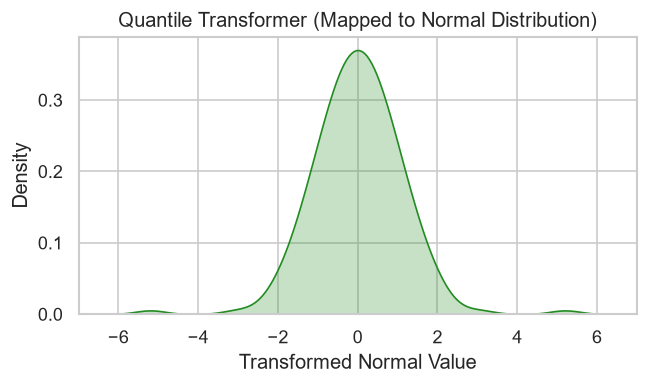

In [19]:
np.random.seed(42)
skewed_data = np.random.exponential(scale=2, size=200).reshape(-1, 1)
qt = QuantileTransformer(n_quantiles=100, output_distribution='normal', random_state=42)
normal_quant = qt.fit_transform(skewed_data)
print("Quantile Normal Output Summary (Mean/Std):", round(normal_quant.mean(), 2), round(normal_quant.std(), 2))

# Visualization
plt.figure(figsize=(6, 3))
sns.kdeplot(normal_quant.flatten(), color='forestgreen', fill=True)
plt.title('Quantile Transformer (Mapped to Normal Distribution)')
plt.xlabel('Transformed Normal Value')
plt.show()

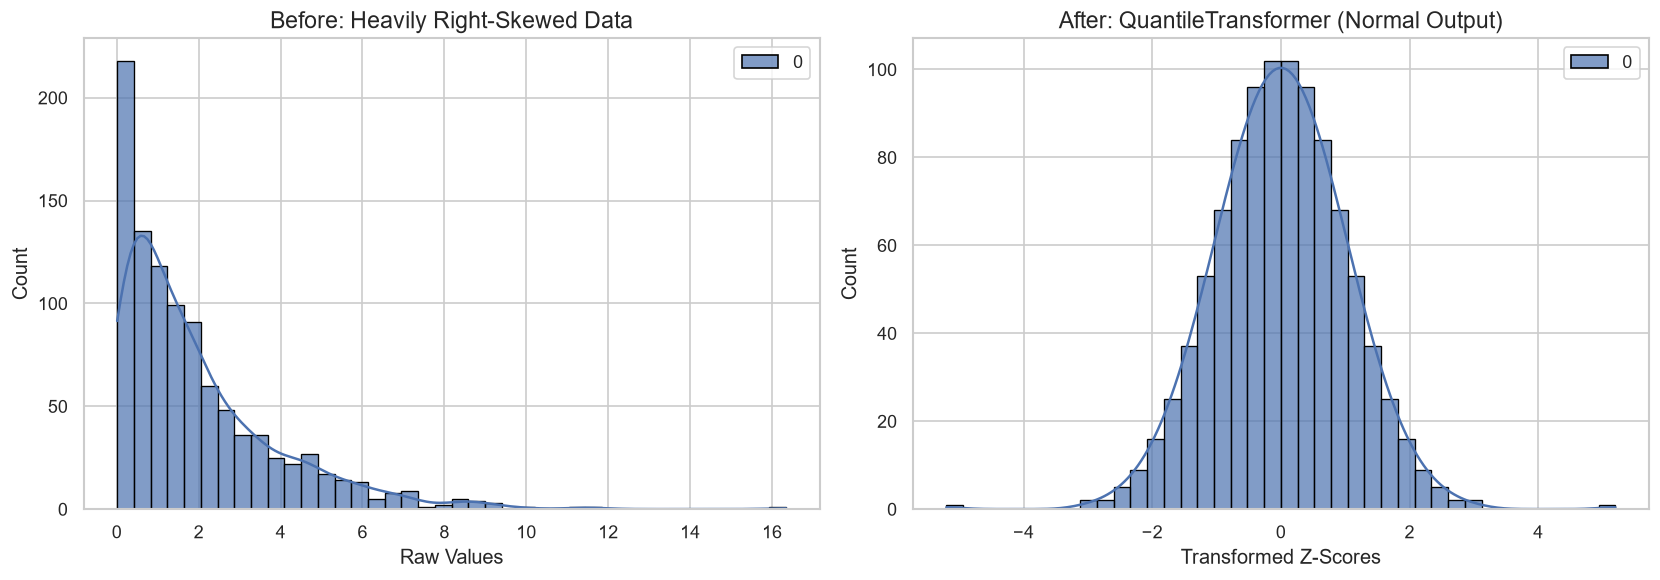

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.preprocessing import QuantileTransformer

# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate right-skewed exponential data (same as your previous example)
skewed_data = np.random.exponential(scale=2, size=1000).reshape(-1, 1)

# 2. Instantiate and apply the QuantileTransformer
# output_distribution='normal' forces the final distribution into a bell curve
qt = QuantileTransformer(output_distribution="normal", random_state=42)
transformed_data = qt.fit_transform(skewed_data)

# 3. Plotting the Before vs After side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.set_theme(style="whitegrid")

# Left Plot: Original Skewed Data
sns.histplot(
    skewed_data,
    kde=True,
    color="crimson",
    bins=40,
    ax=axes[0],
    edgecolor="black",
    alpha=0.7,
)
axes[0].set_title("Before: Heavily Right-Skewed Data", fontsize=14)
axes[0].set_xlabel("Raw Values")
axes[0].set_ylabel("Count")

# Right Plot: Quantile Transformed Data
sns.histplot(
    transformed_data,
    kde=True,
    color="teal",
    bins=40,
    ax=axes[1],
    edgecolor="black",
    alpha=0.7,
)
axes[1].set_title("After: QuantileTransformer (Normal Output)", fontsize=14)
axes[1].set_xlabel("Transformed Z-Scores")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

---
## Summary Table

| Scaling / Transformation Technique | Core Mathematical Operation | Outlier Sensitivity | Primary Analytical Purpose |
| :--- | :--- | :--- | :--- |
| **Standardization** | Zero mean, unit variance ($Z$-score) | High (skews mean and variance) | Preparing features for gradient descent and distance metrics |
| **Min-Max Scaling** | Bounding values within range $[0, 1]$ | High (compresses non-outliers) | Bounding features to fixed intervals |
| **Robust Scaler** | Median subtraction and IQR division | Low (outlier-resilient) | Scaling outlier-heavy datasets safely |
| **Power Transforms (Box-Cox / Yeo-Johnson)** | Non-linear power optimization | Moderate | Stabilizing variance and transforming skewed data to Gaussian |
| **Quantile Transforms** | CDF rank mapping (Uniform / Normal) | Very Low (forces shape) | Forcing arbitrary distributions into uniform or normal shapes |

In [21]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import (
    MinMaxScaler,
    QuantileTransformer,
    StandardScaler,
)

# 1. Real-time Crypto Prices Column (Top 10 by Market Cap)
crypto_data = {
    "Asset": [
        "Bitcoin (BTC)",
        "Ethereum (ETH)",
        "Zcash (ZEC)",
        "BNB",
        "XRP",
        "Tether (USDT)",
        "USDC",
        "Solana (SOL)",
        "Hyperliquid (HYPE)",
        "WhiteBIT (WBT)",
    ],
    "Price_USD": [
        74580.41,
        2112.56,
        1145.12,
        689.23,
        1.10,
        0.9987,
        0.9998,
        86.02,
        74.56,
        71.99,
    ],
}

df = pd.DataFrame(crypto_data)
raw_prices = df[["Price_USD"]].values

# 2. Apply the Three Distinct Scaling Approaches
df["MinMax_Scaled"] = MinMaxScaler().fit_transform(raw_prices)
df["Standard_Scaled"] = StandardScaler().fit_transform(raw_prices)
df["Quantile_Scaled"] = QuantileTransformer(
    output_distribution="normal", random_state=42, n_quantiles=10
).fit_transform(raw_prices)

# Display the 10 rows in a structured format
print(df.to_string(index=False))

             Asset  Price_USD  MinMax_Scaled  Standard_Scaled  Quantile_Scaled
     Bitcoin (BTC) 74580.4100   1.000000e+00         2.998689         5.199338
    Ethereum (ETH)  2112.5600   2.831293e-02        -0.259109         1.220640
       Zcash (ZEC)  1145.1200   1.534098e-02        -0.302601         0.764710
               BNB   689.2300   9.228168e-03        -0.323095         0.430727
               XRP     1.1000   1.358284e-06        -0.354030        -0.764710
     Tether (USDT)     0.9987   0.000000e+00        -0.354035        -5.199338
              USDC     0.9998   1.474938e-08        -0.354035        -1.220640
      Solana (SOL)    86.0200   1.140010e-03        -0.350213         0.139710
Hyperliquid (HYPE)    74.5600   9.863486e-04        -0.350728        -0.139710
    WhiteBIT (WBT)    71.9900   9.518887e-04        -0.350843        -0.430727
